Imports

In [19]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer
from nltk.stem import LancasterStemmer
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from scipy.sparse import csr_matrix


ciao


In [20]:

numberStopwords=50
stemmization_Flag=True
lemmization_Flag=True

Load data

In [21]:
train_data = pd.read_csv("data_supervised.csv", encoding="utf8")
target = pd.read_csv("target_supervised.csv", encoding="utf8")
unsupervised_data=pd.read_csv("data_unsupervised.csv", encoding="utf8")
#for each dataset we print for each column the number of elements missing
print(train_data.isnull().sum())
print(target.isnull().sum())
print(unsupervised_data.isnull().sum())
print("Supervised data: Counts of different attribute values observed in each feature:")
print(train_data.nunique())
print("Unsupervised data: Counts of different attribute values observed in each feature:")
print(unsupervised_data.nunique())

author         0
subreddit      0
created_utc    0
body           0
dtype: int64
author    0
gender    0
dtype: int64
author         0
subreddit      0
created_utc    0
body           2
dtype: int64
Supervised data: Counts of different attribute values observed in each feature:
author           5000
subreddit        3468
created_utc    278142
body           289608
dtype: int64
Unsupervised data: Counts of different attribute values observed in each feature:
author          15000
subreddit        3970
created_utc    715561
body           828126
dtype: int64


Only unsupervised_data.csv has 2 comments missing.
We'll also delete comments containing only white spaces

In [ ]:
train_data = train_data[train_data['body'].str.strip().astype(bool)]
unsupervised_data = unsupervised_data[unsupervised_data['body'].str.strip().astype(bool)]
print(unsupervised_data.isnull().sum())

author         0
subreddit      0
created_utc    0
body           0
dtype: int64


Count duplicates

In [23]:
print("Numero totale di commenti:", len(train_data['body']))

print(train_data.duplicated().sum())
print(unsupervised_data.duplicated().sum())  
print(target.duplicated().sum())  

Numero totale di commenti: 296042
7
256137
0


Deletion of duplicated rows

In [24]:
train_data=train_data.drop_duplicates()
unsupervised_data=unsupervised_data.drop_duplicates()
print(train_data.duplicated().sum())
print(unsupervised_data.duplicated().sum())  
print(target.duplicated().sum())  

0
0
0


Removing all links and characters that are not letters and whitespace
This operation will also be performed on the unsupervised dataset but not in this file

In [27]:
train_data['body'] = train_data['body'].str.lower()#to lowercase
train_data['body'] = train_data['body'].str.replace(r'http\S+|www\.\S+', '', regex=True)#remove URLs
train_data['body'] = train_data['body'].str.replace(r'[^a-z\s]', '', regex=True)#remove everything except letters and whitespace
train_data = train_data[train_data['body'].str.strip().astype(bool)]#remove comments with only whitespace
train_data = train_data.dropna()#remove empty comments


Empirical distribution of the number of characterst in each comment

train data


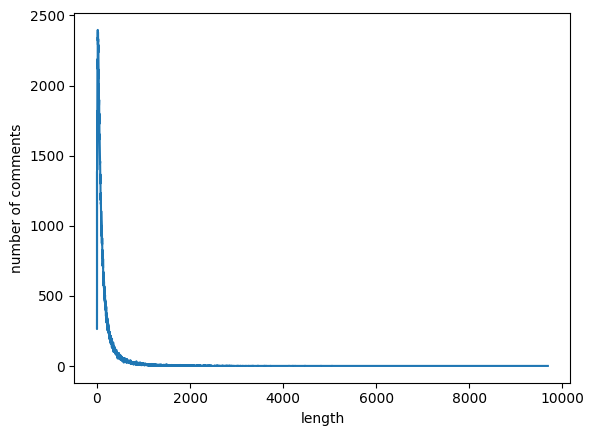

filtered train data


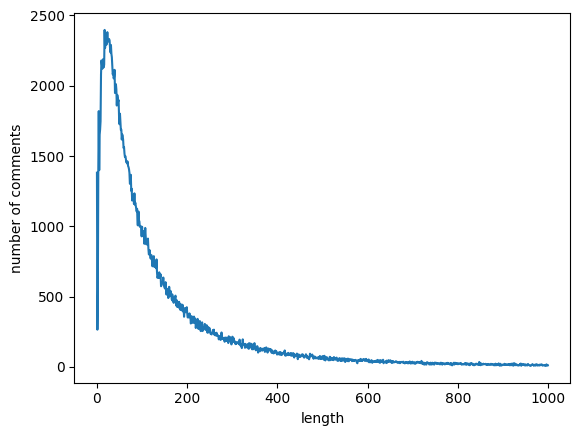

unsupervised data


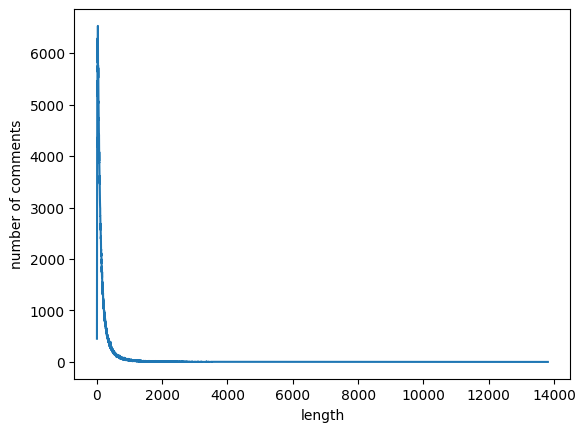

filtered unsupervised data


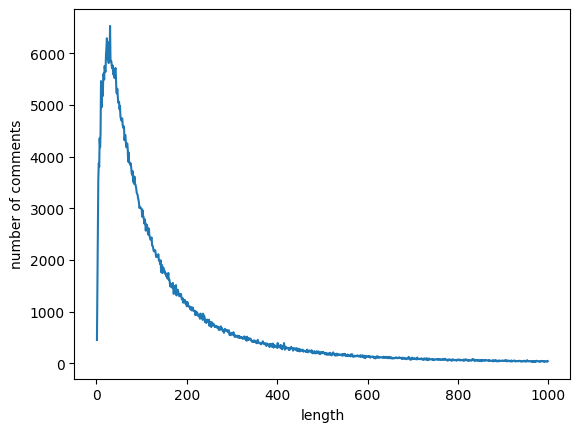

In [9]:
def plotEmpiricalDistributionNumberOfComments(data):

    #we can define a series that has the length as an index and the number of comments that match the length as the value
    countForLenght=data.groupby('length').count()['body']

    #print(countForLenght.max)

    x = countForLenght.index
    y =  countForLenght.values

    df = pd.DataFrame({
        'length' : x, #'length' : x[0:1000], 
        'number of comments' : y#[0:1000]
    })

    plt.figure()
    sns.lineplot(
        data = df, # which dataframe you want to use as the source data
        x = 'length', # which column to use for x-axis
        y = 'number of comments', # which column to use for y-axis
        ax = plt.gca() # assign this plot to current axis, not mandatory in this case
    )
    plt.show()

train_data['length'] = train_data['body'].astype(str).apply(len)
unsupervised_data['length'] = unsupervised_data['body'].astype(str).apply(len)

print("train data")
plotEmpiricalDistributionNumberOfComments(train_data)
print("filtered train data")
plotEmpiricalDistributionNumberOfComments(train_data[train_data['length'] < 1000])
print("unsupervised data")
plotEmpiricalDistributionNumberOfComments(unsupervised_data)
print("filtered unsupervised data")
plotEmpiricalDistributionNumberOfComments(unsupervised_data[unsupervised_data['length'] < 1000])


distribution of the number of comments per author

In [10]:
#save DF as csv
unsupervised_data.groupby('author').count().to_csv("number_of_comments_per_author_unsupervised.csv", index=False)

train data author distribution without outliers


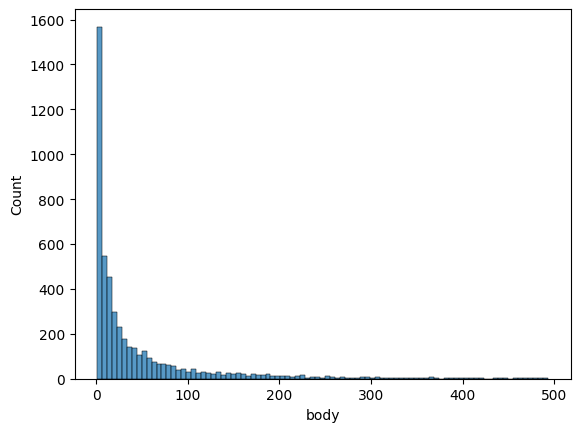

unsupervised data author distribution without outliers


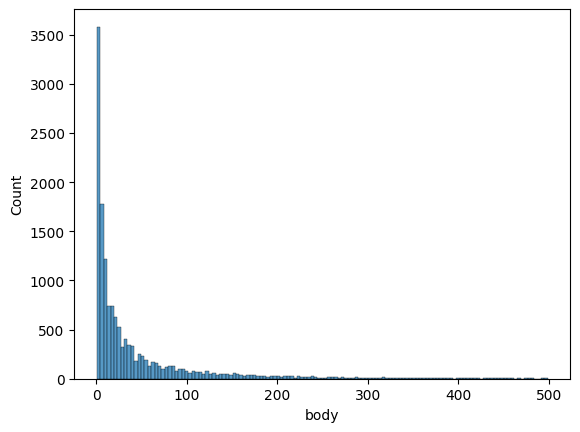

In [11]:
print("train data author distribution without outliers")
plt.figure()
sns.histplot(
    train_data.groupby('author').count()['body'][train_data.groupby('author').count()['body'] < 500]
)
plt.show()

print("unsupervised data author distribution without outliers")
plt.figure()
sns.histplot(
    unsupervised_data.groupby('author').count()['body'][unsupervised_data.groupby('author').count()['body'] < 500]#TODO ricontrollare sta roba
)
plt.show()


In [12]:
#printing the number of males and females
print(target.groupby('gender').count())

#printing the number of comments for males and females
print(pd.merge(target,train_data).groupby('gender').count())

        author
gender        
0         3651
1         1349
        author  subreddit  created_utc    body  length
gender                                                
0       228651     228651       228651  228651  228651
1        67384      67384        67384   67384   67384


ENGLISH COMMENT

In [ ]:
from langdetect import detect, DetectorFactory
DetectorFactory.seed = 0  # rende i risultati stabili

# Assicuriamoci che 'body' sia stringa
train_data['body'] = train_data['body'].fillna('').astype(str)

# Applichiamo il rilevamento lingua gestendo errori e testi vuoti
langs = []
for text in train_data['body']:
    # if not text.strip():  # se la riga del commento è vuota
    #     langs.append("empty")
    # else:
    try:
        langs.append(detect(text))
    except:
        langs.append("error")

train_data['language'] = langs

# Conta quante frasi ci sono per ciascuna lingua
counts = train_data['language'].value_counts()
print(counts)

language
en    265633
cy      2628
af      2278
so      2247
fr      1810
da      1612
it      1600
nl      1557
no      1557
tl      1298
et      1152
tr      1004
ca       979
sv       908
es       881
id       872
fi       762
pl       728
ro       679
sw       623
pt       594
sq       524
hr       486
sl       469
de       441
sk       325
cs       250
lt       166
vi       164
lv       133
hu       106
Name: count, dtype: int64


In [ ]:
train_data_en = train_data[train_data["language"] == "en"]
print("Forma filtrata (solo inglese, soglia 0.4):", train_data_en.shape)

Forma filtrata (solo inglese, soglia 0.4): (268102, 6)


In [ ]:
print(train_data.head(10))
from langdetect import detect_langs
import pandas as pd

# Supponiamo che train_data sia già caricato e contenga la colonna "body"
ambigui = []

for i, commento in enumerate(train_data["body"]):
    try:
        langs = detect_langs(commento)
        best = langs[0]  # lingua con la probabilità più alta
        if best.prob < 0.80:   # soglia di confidenza
            ambigui.append((i, commento[:100], langs))  # salvo i casi incerti
    except:
        ambigui.append((i, commento[:100], "Errore"))

# Mostra i primi 10 casi incerti
for riga in ambigui[:10]:
    print(riga)

          author          subreddit   created_utc  \
0    Shamus_Aran       mylittlepony  1.388534e+09   
1       Riddance                sex  1.388534e+09   
2  Secret_Wizard       DragonsDogma  1.388534e+09   
3   Penultimatum  malefashionadvice  1.388534e+09   
4      7-SE7EN-7      todayilearned  1.388534e+09   
5        Sahil17       Christianity  1.388534e+09   
6         spyfer      NetflixBestOf  1.388534e+09   
7         tehftw          AskReddit  1.388534e+09   
8      timsstuff             movies  1.388534e+09   
9  Bullseye4hire             hockey  1.388534e+09   

                                                body language  
0  I don't think we'd get nearly as much fanficti...       en  
1  Thanks. I made it up, that's how I got over my...       en  
2  Are you sure you aren't confusing Cyclops (the...       en  
3                             dont do this to me bro       pt  
4        That's what we do when we can't find a mate       en  
5  Damn I love this question. He

In [ ]:
def rileva_lingua(testo):
    try:
        langs = detect_langs(testo)
        best = langs[0]  # lingua più probabile
        if best.lang == "en" and best.prob >= 0.4:   # soglia di confidenza
            return "en"
        else:
            return best.lang # troppo dubbio
    except:
        return "error"  # non rilevabile

# Applichiamo il rilevamento lingua alla colonna "body"
train_data["lang"] = train_data["body"].astype(str).apply(rileva_lingua)

# Filtra SOLO righe in inglese
train_data_en = train_data[train_data["lang"] == "en"]

print("Forma iniziale:", train_data.shape)
print("Forma filtrata (solo inglese):", train_data_en.shape)

# Se vuoi sovrascrivere
train_data = train_data_en.reset_index(drop=True)


Forma iniziale: (296035, 5)
Forma filtrata (solo inglese): (269525, 5)


In [ ]:
train_data=train_data.map(lambda x: x.lower() if isinstance(x, str) else x)
target=target.map(lambda x: x.lower() if isinstance(x, str) else x)
unsupervised_data=unsupervised_data.map(lambda x: x.lower() if isinstance(x, str) else x)


In [ ]:
#train_data['body'].str.split().explode()

MostFrequentWords = train_data['body'].str.split().explode().value_counts()[0:numberStopwords].index.tolist()
print(MostFrequentWords)
for word in MostFrequentWords:
    train_data['body']=train_data['body'].str.replace(rf'\b{word}\b', '', regex=True)
MostFrequentWords = train_data['body'].str.split().explode().value_counts()[0:numberStopwords].index.tolist()
print(MostFrequentWords)


NameError: name 'numberStopwords' is not defined

In [ ]:
#lemmization

# Function to tokenize and lemmatize a single text
def lemmatize_text(text,lemmatizer):
    # Tokenize the text into words
    tokens = word_tokenize(text)
    
    # Lemmatize each token
    lemmatized_words = []
    for word in tokens:
        lemmatized_word = lemmatizer.lemmatize(word)
        lemmatized_words.append(lemmatized_word)
    
    # Join the lemmatized words back into a single string
    lemmatized_text = ' '.join(lemmatized_words)
    return lemmatized_text

def lemmization(df):
    # Initialize the lemmatizer
    lemmatizer = WordNetLemmatizer()

    # Apply the lemmatization function to the DataFrame column
    for index, row in train_data.iterrows():
        lemmatized_result = lemmatize_text(row['body'],lemmatizer)  # Process each row
        df.at[index, 'body'] = lemmatized_result



In [ ]:
# Print the resulting DataFrame
print(train_data['body'][0])
print(train_data.shape)

  think 'd  nearly  much fanfiction  pictures shipping ban-ban  lyro.  saying.
(296035, 5)


In [ ]:
#stemming
def stemmer_text(text,stemmer):
    # Tokenize the text into words
    tokens = word_tokenize(text)
    #tokens = text.split(' ')#what if we don't tokenize?
    stemmer_words = []
    for word in tokens: 
        stemmer_words.append(stemmer.stem(word))
    
    stemmed_text = ' '.join(stemmer_words)
    return stemmed_text

def stemmization(df):
    stemmer = LancasterStemmer()

    for index, row in train_data.iterrows():
        stemmed_result = stemmer_text(row['body'],stemmer)  # Process each row
        df.at[index, 'body'] = stemmed_result


In [ ]:
print(train_data['body'][0])

  think 'd  nearly  much fanfiction  pictures shipping ban-ban  lyro.  saying.


In [ ]:
#grouping by the author
train_data=train_data[['author','body']].groupby('author').agg(' '.join).reset_index()
print(train_data.head(3))
vectorizerCount = CountVectorizer()
vectorizerCount.fit(train_data['body'])
vectorizerCount = vectorizerCount.transform(train_data['body'])

     author                                               body
0  -evasian  i just received my deathadder black edition ye...
1    -jared  neil diamond - sweet caroline +1 on the chirop...
2   -peeter                         just read the faq, really.


In [ ]:
print(vectorizerCount.shape)
#print(csr_matrix(vectorizerCount.toarray()))
#print(len(vectorizerCount.vocabulary_))


(4944, 137483)


In [ ]:
vectorizerTfidf = TfidfVectorizer()
vectorizerTfidf.fit(train_data['body'])
#print(sorted(vectorizerTfidf.vocabulary_))
vectorizerTfidf = vectorizerTfidf.transform(train_data['body'])
print(vectorizerTfidf[2])
#vectorizerTfidf.fit(unsupervised_data['body'])
#print(sorted(vectorizerTfidf.vocabulary_))
#vectorizerTfidf = vectorizerTfidf.transform(unsupervised_data['body']))

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 5 stored elements and shape (1, 137483)>
  Coords	Values
  (0, 49325)	0.8494306823036974
  (0, 69730)	0.22267455053143276
  (0, 100806)	0.35866820778839553
  (0, 100898)	0.258011512965322
  (0, 120868)	0.1834958757190616


4. Reduce the complexity of your dataset.

In [ ]:
#pca=PCA(n_components=PCA_number_components,random_state=42,)
#pca.fit(vectorizerTfidf)

from sklearn.decomposition import TruncatedSVD
import numpy as np

# Supponiamo di avere X_tfidf dal tuo TfidfVectorizer
n_components = 2000  # numero di componenti iniziale

svd = TruncatedSVD(n_components=n_components, random_state=42)
X_reduced = svd.fit_transform(vectorizerCount)

# Calcola la varianza spiegata cumulativa
explained_var = np.sum(svd.explained_variance_ratio_)
print(f"Cumulative explained variance with {n_components} components: {explained_var:.2%}")
import pandas as pd

# Converti l'array numpy in un DataFrame
df_reduced = pd.DataFrame(X_reduced)
#aggiungi la colonna author
df_reduced.insert(0, "author", train_data["author"].values)


# Salva in un file CSV
df_reduced.to_csv("X_reduced_svd.csv", index=True)
print(df_reduced[1])
print("File salvato come X_reduced_svd.csv")



Cumulative explained variance with 2000 components: 99.98%
0      -8.323029
1      -0.378251
2      -0.163695
3      -0.534567
4      -0.241359
          ...   
4939   -1.732167
4940   -6.443540
4941    7.169717
4942    0.305228
4943   -0.520517
Name: 1, Length: 4944, dtype: float64
File salvato come X_reduced_svd.csv


In [ ]:

# carico il file con le etichette (deve avere colonne ['author', 'gender'])
df_labels = pd.read_csv("target_supervised.csv")
#puliscom le colonne author
df_reduced['author'] = df_reduced['author'].str.strip().str.lower()
df_labels['author'] = df_labels['author'].str.strip().str.lower()


# unisco sul campo 'author'
df_final = pd.merge(df_reduced, df_labels, on="author", how="inner")

# porto 'gender' in prima colonna
cols = ['gender'] + [c for c in df_final.columns if c != 'gender']
df_final = df_final[cols]

# salvo il dataset pronto
df_final.to_csv("X_reduced_with_labels.csv", index=False)



In [ ]:
#df_reduced['author'].duplicated().sum()
df_labels['author'].duplicated().sum()
# autori presenti in X_reduced ma non in labels
missing_in_labels = set(df_reduced['author']) - set(df_labels['author'])
print("Autori mancanti in labels:", missing_in_labels)

# autori presenti in labels ma non in X_reduced
missing_in_reduced = set(df_labels['author']) - set(df_reduced['author'])
print("Autori mancanti in X_reduced:", missing_in_reduced)



Autori mancanti in labels: set()
Autori mancanti in X_reduced: {'wtfwaffles', 'yellieee', 'eodoperative', 'kanpai_slainte', 'msmkat', 'bkling', 'cakewedge', 'gearhead90', 'rickgene', 'spudtastic', 'maniactigris', 'jacked-t', 'kingpanday', 'crankytank', 'plecter', 'poiar', 'ex_temporaneous', 'slendermanx', 'ppity', 'jetersauce', 'slive', 'doctordm', 'aartimus_prime', 'welshcorgis', 'mrmmmmm', 'cywanese', 'blaxk', '_bookworm', 'ss15', 'siim555', 'whygodwhyyy', 'train1231', 'jorikk', 'octahedron8', 'ultimate_ging', 'hellohurricane801', 'krippling', 'lyssalyssalyssa', 'drewnonumber', 'alexoftheyear', 'chanaynay', 'emilyla', 'cloakwandstone', 'redditat-tat', 'sddcsurf', 'sigtrap', 'puddums', 'blueberry_nutsack', 'wxns', 'monkeytoes_', 'baturkey', 'kev92685', 'aafroking', 'bsod666rrod', 'isleepalot', 'neverahappyending342'}


In [ ]:
# # describe how much of the dataset variability is indicated by a given amount of features
# explained_variance = pca.explained_variance_ratio_

# # evaluate the total dataset variability while increasing the variables
# cumul_exp_var = np.cumsum(explained_variance)

# # percentage value to better understand the best number of components
# perc_cumul_exp_var = cumul_exp_var * 100

# # make the plot of cumulative explained variance wrt number of components

# plt.figure(figsize=(5, 3.5))
# plt.plot(perc_cumul_exp_var, marker='o')
# plt.xlabel('# Principal Components (PCs)')
# plt.ylabel('Cumulative explained variance [%]')
# plt.xticks([i for i in range(PCA_number_components)], [i for i in range(1,PCA_number_components+1)])
# plt.grid()
# plt.title(f'{(PCA_number_components/2)-1} PCs explain {round(perc_cumul_exp_var[int(PCA_number_components/2)], 2)}% of $\sigma^2$')
# plt.tight_layout()
# plt.show()

# print(perc_cumul_exp_var[-1])
# pca_result = pca.transform(vectorizerTfidf)

# dfPCA=pd.DataFrame(pca_result)
# dfPCA.to_csv("PCA.csv")
# print(dfPCA.shape)